# Advertising Sales — Linear Regression with Gradient Descent

## Notebook purpose

This notebook studies how the advertising budget for **TV**, **Radio**, or
**Newspaper** relates to **Sales**. A small linear-regression class is built
from scratch so that the training process can be inspected instead of hidden
behind a library call.

## Workflow

1. Load and inspect the advertising dataset.
2. Explore correlations and feature/target relationships.
3. Split each experiment into training and test sets.
4. Train a one-feature linear model with gradient descent.
5. Plot the cost history and fitted line, then evaluate with $R^2$.

The three univariate experiments are intentionally separate: they answer which
single advertising channel is the most useful predictor of Sales.

## Mathematical foundations

For a linear model, the prediction is the weighted sum of the input features:

$$
\hat{y} = X\theta
$$

The notebooks add a column of ones to $X$ when the intercept is learned as one
of the parameters in $\theta$. The objective is the half mean-squared error:

$$
J(\theta) = \frac{1}{2m}\sum_{i=1}^{m}(\hat{y}^{(i)}-y^{(i)})^2
$$

Its gradient is:

$$
\nabla_\theta J(\theta) = \frac{1}{m}X^T(X\theta-y)
$$

Gradient descent repeatedly updates the parameters in the direction that
reduces the cost:

$$
\theta \leftarrow \theta - \alpha\nabla_\theta J(\theta)
$$

where $m$ is the number of observations and $\alpha$ is the learning rate.
Model quality is reported with mean squared error and the coefficient of
determination:

$$
\mathrm{MSE}=\frac{1}{m}\sum_{i=1}^{m}(y_i-\hat{y}_i)^2,
\qquad
R^2=1-\frac{\sum_i(y_i-\hat{y}_i)^2}{\sum_i(y_i-\bar{y})^2}
$$


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
import seaborn as sns
from sklearn.preprocessing import StandardScaler

In [ ]:
dataset=pd.read_csv("data/Advertising.csv")
dataset.head()

,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,12.0
3,151.5,41.3,58.5,16.5
4,180.8,10.8,58.4,17.9


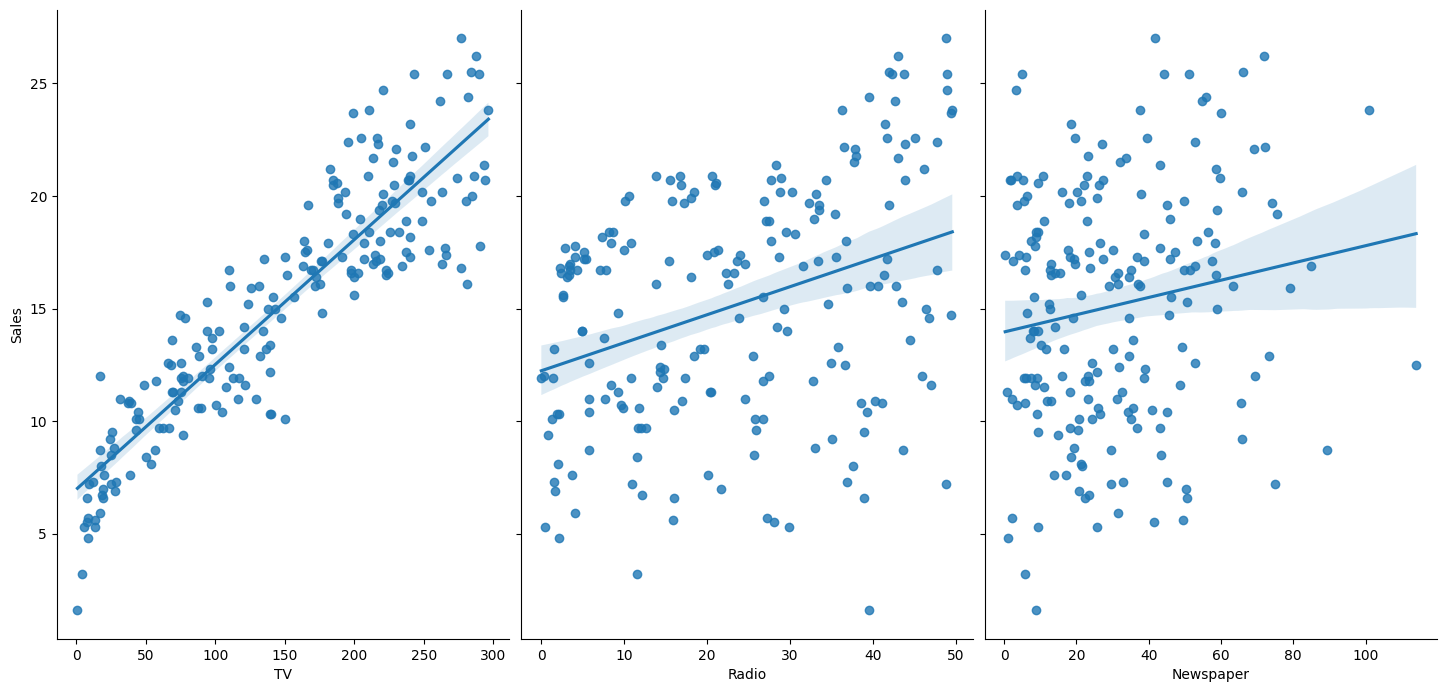

In [ ]:
sns.pairplot(dataset, x_vars=['TV', 'Radio', 'Newspaper'], y_vars='Sales', height=7, aspect=0.7, kind='reg')

<Axes: >

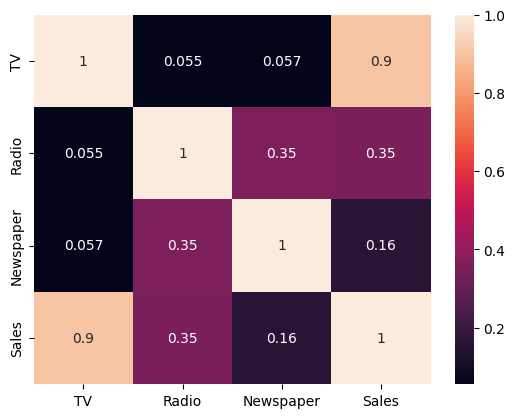

In [ ]:
sns.heatmap(dataset.corr(), annot=True)

In [ ]:
dataset.describe()

,TV,Radio,Newspaper,Sales
count,200.000000,200.000000,200.000000,200.000000
mean,147.042500,23.264000,30.554000,15.130500
std,85.854236,14.846809,21.778621,5.283892
min,0.700000,0.000000,0.300000,1.600000
25%,74.375000,9.975000,12.750000,11.000000
50%,149.750000,22.900000,25.750000,16.000000
75%,218.825000,36.525000,45.100000,19.050000
max,296.400000,49.600000,114.000000,27.000000


In [ ]:
class LinearRegression:
    def __init__(self, learning_rate):
        self.learning_rate = learning_rate
        self.a = None
        self.b = None

    def initialize_parameters(self, n):
        self.a = np.random.randn(n) * 0.01
        self.b = 0

    def model(self, X):
        return np.dot(X, self.a) + self.b

    def compute_cost(self, predictions):
        m = len(predictions)
        return np.sum(predictions - self.y)**2 / (2 * m)

    def grad(self, predictions):
        m = len(predictions)
        self.da = self.X.T.dot(predictions - self.y) / m
        self.db = np.sum(predictions - self.y) / m

    def fit(self, X, y, iterations):
        self.X = X
        self.y = y
        self.initialize_parameters(X.shape[1])
        costs = []

        for i in range(iterations):
            predictions = self.model(X)
            cost = self.compute_cost(predictions)
            self.grad(predictions)
            self.a -= self.learning_rate * self.da
            self.b -= self.learning_rate * self.db
            costs.append(cost)

            if i % 100 == 0:
                print(f'Iteration: {i}, Cost: {cost}')

        plt.plot(costs)
        plt.xlabel('Iterations')
        plt.ylabel('Cost')
        plt.title('Cost Function')
        plt.show()

    def predict(self, X):
        return self.model(X)

    def evaluate(self, X, y):
        y_pred = self.predict(X)
        u = np.sum(np.square(y - y_pred))
        v = np.sum(np.square(y - np.mean(y)))
        return 1 - u/v

    def plot(self, X, y):
        plt.scatter(X, y)
        plt.plot(X, self.predict(X), color='red')
        plt.xlabel('feature')
        plt.ylabel('target')
        plt.title('feature vs target')
        plt.show()


### TV vs Sales


In [ ]:
X = dataset[['TV']].values
y = dataset['Sales'].values
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


Iteration: 0, Cost: 20462.900225105255
Iteration: 100, Cost: 224.8867164788478
Iteration: 200, Cost: 224.7790891943866
Iteration: 300, Cost: 224.67151341867225
Iteration: 400, Cost: 224.56398912705058
Iteration: 500, Cost: 224.4565162948822
Iteration: 600, Cost: 224.3490948975394
Iteration: 700, Cost: 224.24172491040682
Iteration: 800, Cost: 224.13440630887976
Iteration: 900, Cost: 224.0271390683667
Iteration: 1000, Cost: 223.91992316428565
Iteration: 1100, Cost: 223.81275857206884
Iteration: 1200, Cost: 223.70564526715893
Iteration: 1300, Cost: 223.59858322501054
Iteration: 1400, Cost: 223.49157242108996
Iteration: 1500, Cost: 223.38461283087662
Iteration: 1600, Cost: 223.27770442985837
Iteration: 1700, Cost: 223.1708471935387
Iteration: 1800, Cost: 223.06404109742948
Iteration: 1900, Cost: 222.95728611705727
Iteration: 2000, Cost: 222.85058222795755
Iteration: 2100, Cost: 222.74392940568003
Iteration: 2200, Cost: 222.6373276257835
Iteration: 2300, Cost: 222.5307768638413
Iteration: 2

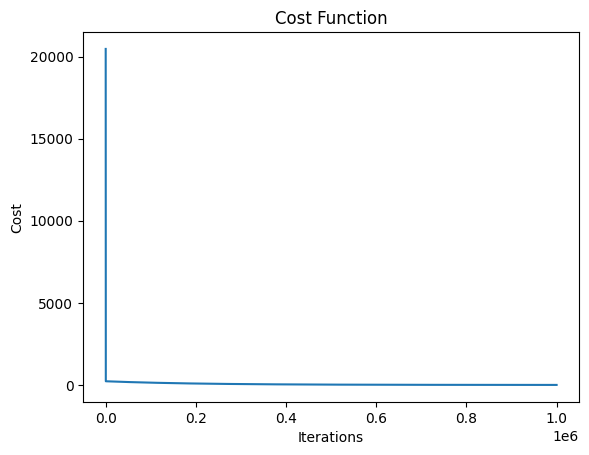

In [ ]:
model = LinearRegression(0.00001)
model.fit(X_train, y_train, 1000000)

R2 Score :  0.800169711008101


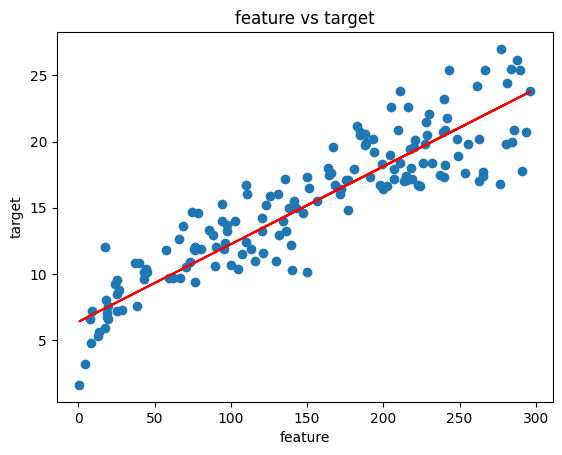

In [ ]:
tv_r2 = model.evaluate(X_test, y_test)
print("R2 Score : ", tv_r2)
model.plot(X_train, y_train)

# Radio vs Sales


In [ ]:
X = dataset[['Radio']].values
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


Iteration: 0, Cost: 18942.134362179604
Iteration: 100, Cost: 6837.44176175842
Iteration: 200, Cost: 3202.4718438671184
Iteration: 300, Cost: 1952.7914746902104
Iteration: 400, Cost: 1466.599373589233
Iteration: 500, Cost: 1259.6679334446023
Iteration: 600, Cost: 1166.55227059197
Iteration: 700, Cost: 1123.2406201381966
Iteration: 800, Cost: 1102.6204138950366
Iteration: 900, Cost: 1092.5586159148465
Iteration: 1000, Cost: 1087.4614393582788
Iteration: 1100, Cost: 1084.7106476335853
Iteration: 1200, Cost: 1083.07161829202
Iteration: 1300, Cost: 1081.9600802294478
Iteration: 1400, Cost: 1081.0990594632913
Iteration: 1500, Cost: 1080.3571489734088
Iteration: 1600, Cost: 1079.671979953681
Iteration: 1700, Cost: 1079.0139451957948
Iteration: 1800, Cost: 1078.3689885134913
Iteration: 1900, Cost: 1077.730436315689
Iteration: 2000, Cost: 1077.0951199941742
Iteration: 2100, Cost: 1076.4615350255622
Iteration: 2200, Cost: 1075.8289669664764
Iteration: 2300, Cost: 1075.197076493003
Iteration: 240

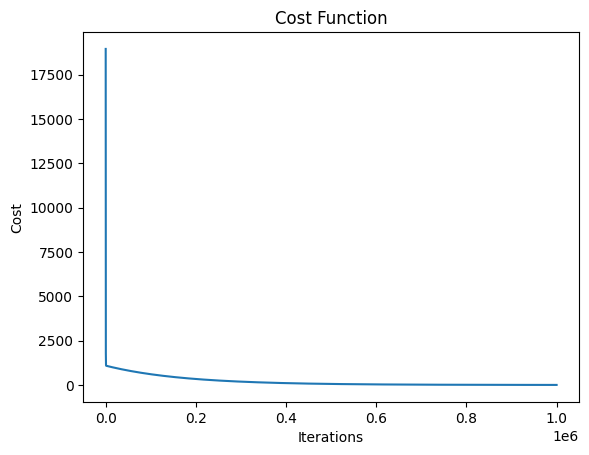

In [ ]:
model = LinearRegression(0.00001)
model.fit(X_train, y_train, 1000000)

R2 Score :  0.12460784486922749


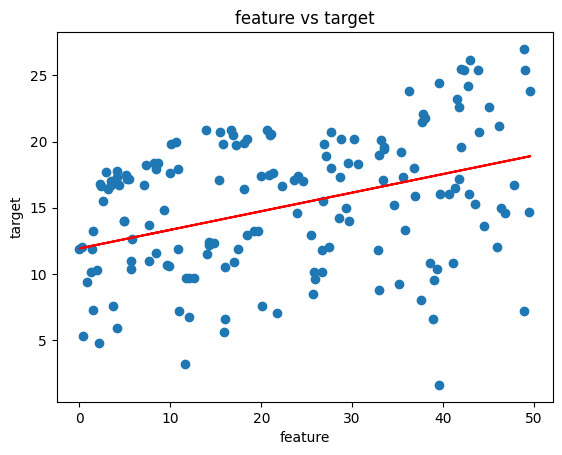

In [ ]:
radio_r2 = model.evaluate(X_test, y_test)
print("R2 Score : ", radio_r2)
model.plot(X_train, y_train)

# Newpapers vs Sales


In [ ]:
X = dataset[['Newspaper']].values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


Iteration: 0, Cost: 20601.240498127543
Iteration: 100, Cost: 4578.779075176399
Iteration: 200, Cost: 2240.2670585479896
Iteration: 300, Cost: 1753.4296473121553
Iteration: 400, Cost: 1632.3706994653617
Iteration: 500, Cost: 1599.938106771598
Iteration: 600, Cost: 1590.5729520593236
Iteration: 700, Cost: 1587.3385087474578
Iteration: 800, Cost: 1585.7431228243008
Iteration: 900, Cost: 1584.5869535122174
Iteration: 1000, Cost: 1583.5488643383787
Iteration: 1100, Cost: 1582.542858049275
Iteration: 1200, Cost: 1581.5459019581072
Iteration: 1300, Cost: 1580.5518267661857
Iteration: 1400, Cost: 1579.5589798018561
Iteration: 1500, Cost: 1578.5669181256444
Iteration: 1600, Cost: 1577.575522813675
Iteration: 1700, Cost: 1576.58476172687
Iteration: 1800, Cost: 1575.5946259708396
Iteration: 1900, Cost: 1574.6051128772656
Iteration: 2000, Cost: 1573.616221445607
Iteration: 2100, Cost: 1572.6279511221908
Iteration: 2200, Cost: 1571.6403014732239
Iteration: 2300, Cost: 1570.653272097196
Iteration: 2

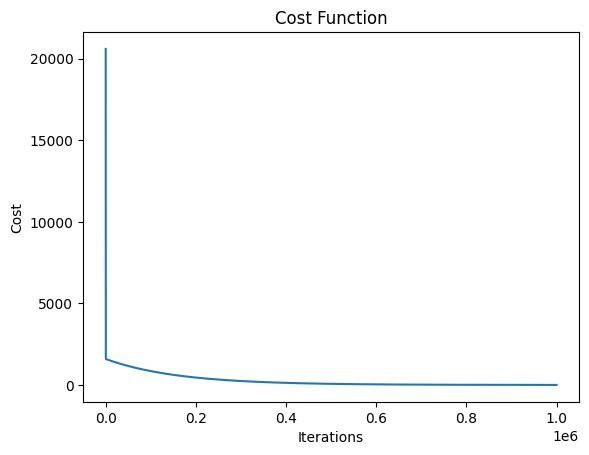

In [ ]:
model = LinearRegression(0.00001)
model.fit(X_train, y_train, 1000000)

R2 Score :  0.015080806363174104


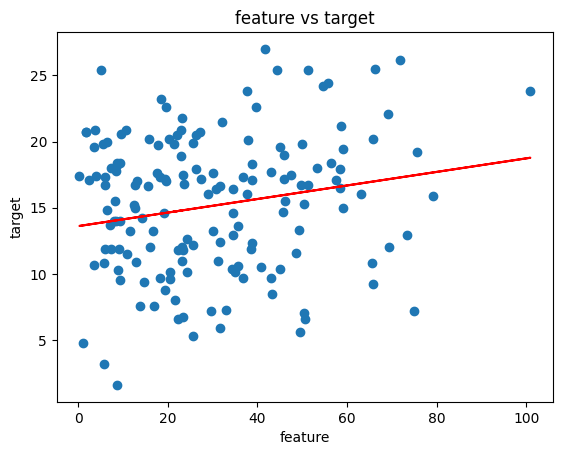

In [ ]:
newspaper_r2 = model.evaluate(X_test, y_test)
print("R2 Score : ", newspaper_r2)
model.plot(X_train, y_train)

### Conclusion


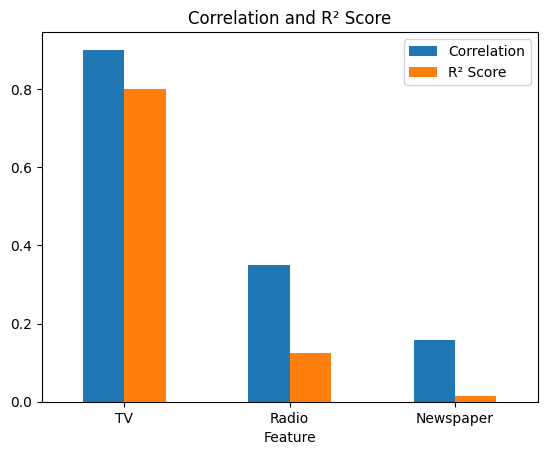

In [ ]:
features = ['TV', 'Radio', 'Newspaper']
r2_scores = [tv_r2, radio_r2, newspaper_r2]
correlation = dataset.corr()['Sales'][features]

plot_data = pd.DataFrame({
    'Feature': features,
    'Correlation': correlation.values,
    'RÂ² Score': r2_scores
})

plot_data.plot(kind='bar', x='Feature', rot=0)
plt.title('Correlation and RÂ² Score')
plt.show()
